# 15 - Capillary Pressure & Saturation-Height

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/15_capillary_pressure_saturation_height.ipynb)

**Part B - Petrophys Curriculum**

Water saturation from resistivity (Archie) tells you the fluid content *at each
depth independently*. A **saturation-height model** does something different and
deeper: it predicts $S_w$ from the **rock quality (porosity, permeability)** and
the **height above the free-water level (FWL)**, grounded in the physics of
**capillary pressure**. It lets you populate $S_w$ where logs are poor, build a
consistent 3-D saturation model, and QC the resistivity-based $S_w$.

This lesson demonstrates the `petrophys.interpretation.saturation.height`
module - capillary-pressure primitives, the Leverett J-function, a fitted
J-function model, and a log-column Sw-vs-depth predictor - using the COSTA
carbonate well **HW-3**. Its LAS file covers only the **Kharaib-2 reservoir
interval**, not the whole well. The laboratory $P_c$ is the bundled
COSTA plug mercury-injection data (110 plugs, section 2b): a Thomeer fit per plug,
a J-function from core and, matched to the logs of HW-24, a free-water level. The
plugs carry no well or depth, so HW-3 also gets a J-function fitted the field way,
from its core-corrected rock-quality curves and an assumed FWL, as a contrast; the
library's single-plug lab-curve fitter (`fit_brooks_corey`) is referenced but not
demonstrated.

Section 3b adds a separate real-data FWL interpretation for **35/11-13** using
MDT formation pressures, compared with the free-water level of the well's report. Its contact is not used
as the FWL of HW-3.

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Convert between **capillary pressure ($P_c$)** and **height above the FWL**,
  and understand the buoyancy that lifts hydrocarbon into the pore system.
- Convert a **laboratory** Pc (air-mercury) to **reservoir** conditions.
- Read plug mercury-injection curves, fit a **Thomeer** hyperbola to each plug
  and read its entry pressure.
- Normalise Pc across rock qualities with the **Leverett J-function**, and
  **fit** one ($S_w = a\,J^b$) to plug data or to log saturations.
- Find the **FWL from logs** with a core model, and place the water contact
  above it by the entry-pressure height.
- Predict **$S_w$ versus depth from logs** with a fitted model + an FWL depth,
  and overlay it on the log-derived $S_w$.
- Fit oil/water pressure gradients using QC-selected MDT points on a TVD datum,
  and compare their intersection with a reported FWL.

## Why this matters (the physics)

Above the free-water level, buoyancy of the lighter hydrocarbon against the
denser water creates a **capillary pressure** that forces water out of the
larger pores first. In field units:

$$P_c = 0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})\,h \quad [\text{psi}],\; h\text{ in ft}$$

so **height above the FWL is just a rescaled capillary pressure**. At a given
height, a *tight* rock (small pores, high entry pressure) holds **more** water
than a *good* rock. To compare rocks of different quality on one curve, Leverett
defined the dimensionless **J-function**:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\,\sqrt{\frac{k}{\phi}}$$

which folds in each rock's $k/\phi$. Fitting $S_w = a\,J^b$ once then lets us map
**any** ($k,\phi,h$) triple to a saturation - the engine of a saturation-height
model.

### Prerequisites
Work through Part A water-saturation (07) and permeability (08) first. Knowing
Archie $S_w$ and the porosity/permeability curves will make the log overlay at
the end meaningful.

In [2]:
import numpy as np
import pandas as pd
import petrophys as pp
from petrophys.interpretation.saturation.height import (
    pc_from_height, convert_pc_lab_to_reservoir, FLUID_SYSTEMS,
    read_capillary_pressure, fit_j_function_from_core, find_fwl, water_contact_from_fwl,
    fit_j_function_from_well, saturation_height_from_logs,
)

pd.set_option("display.precision", 3)

`FLUID_SYSTEMS` holds the interfacial tension and contact angle of the usual
laboratory and reservoir fluid pairs:

In [3]:
pd.DataFrame(FLUID_SYSTEMS, index=["IFT (dyne/cm)", "contact angle (deg)"]).T

,IFT (dyne/cm),contact angle (deg)
air_mercury,480.0,140.0
air_brine,72.0,0.0
oil_brine,30.0,30.0
gas_brine,50.0,0.0


## 1. Capillary pressure and height above the FWL

The `pc_from_height` / `height_from_pc` pair converts between the two using the
buoyancy gradient $0.433\,(\mathrm{SG}_w - \mathrm{SG}_{hc})$. Below we use an oil
column: water SG = 1.0, oil SG = 0.8, a gradient of 0.0866 psi/ft.

In [4]:
heights = [0, 25, 50, 100, 200, 400]   # ft above FWL
pd.DataFrame({"height above FWL (ft)": heights, "Pc (psi)": pc_from_height(heights, sg_water=1.0, sg_hc=0.8)})

,height above FWL (ft),Pc (psi)
0,0,0.000
1,25,2.165
2,50,4.330
3,100,8.660
4,200,17.320
5,400,34.640


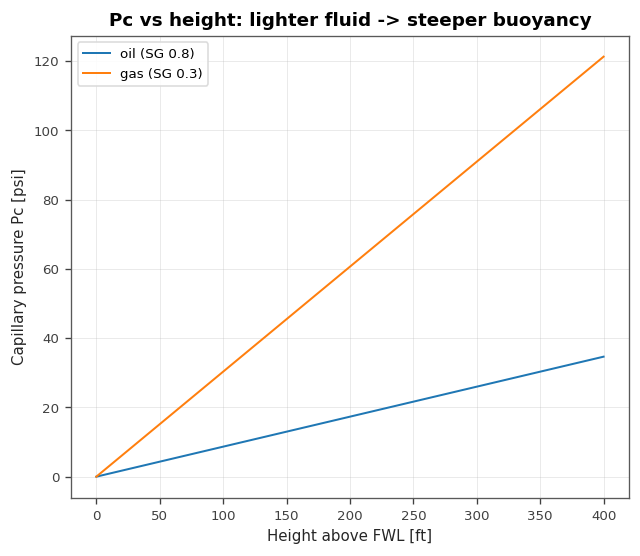

In [5]:
h = np.linspace(0, 400, 100)
pp.line_chart(h, {"oil (SG 0.8)": pc_from_height(h, 1.0, 0.8), "gas (SG 0.3)": pc_from_height(h, 1.0, 0.3)},
              xlabel="Height above FWL [ft]", ylabel="Capillary pressure Pc [psi]",
              title="Pc vs height: lighter fluid -> steeper buoyancy", figsize=(6, 5));

Gas (lower SG) has a larger density contrast with water, so it develops the
same capillary pressure over a **shorter** height - gas columns build $P_c$
faster than oil columns.

## 2. Lab-to-reservoir Pc conversion

Core Pc is usually measured in an **air-mercury** or **air-brine** apparatus,
not at reservoir fluid conditions. The measured $P_c$ scales with the
interfacial tension and wettability of the fluid pair:

$$P_{c,res} = P_{c,lab}\,\frac{(\sigma\cos\theta)_{res}}{(\sigma\cos\theta)_{lab}}$$

`convert_pc_lab_to_reservoir` and the `FLUID_SYSTEMS` table make this a one-liner.

In [6]:
pc_lab = [50, 100, 200, 500]   # psi, air-mercury
pd.DataFrame({"Pc lab air-Hg (psi)": pc_lab,
              "Pc res oil-brine (psi)": convert_pc_lab_to_reservoir(pc_lab, *FLUID_SYSTEMS["air_mercury"],
                                                                    *FLUID_SYSTEMS["oil_brine"])})

,Pc lab air-Hg (psi),Pc res oil-brine (psi)
0,50,3.533
1,100,7.066
2,200,14.131
3,500,35.329


The conversion factor is 0.0707: air-mercury Pc is roughly an **order of
magnitude** higher than the equivalent oil-brine reservoir Pc (about 14x with
the constants used here).

### 2b. Laboratory Pc from the COSTA plugs

The bundled `costa_core_pc` table (Craig Phillips's processed COSTA high-pressure
mercury-injection data) holds the drainage curves of 110 plugs: for each, its
porosity and permeability and a series of mercury pressures with the water
(wetting-phase) saturation left in the plug. `read_capillary_pressure` finds
the columns, turns percent into v/v, and records the fluid system,
air-mercury by default. The plugs carry no well or depth, so they describe the
field's rock, not one well. See the
[dataset notes](https://github.com/sambalshikhar/petrophys/blob/main/src/petrophys/datasets/phillips/README.md).

In [7]:
cap = read_capillary_pressure(pp.sample("costa_core_pc"))
cap

CapillaryPressureData(110 samples, 11055 points, air_mercury Pc 0.299-6.93e+04 psi)

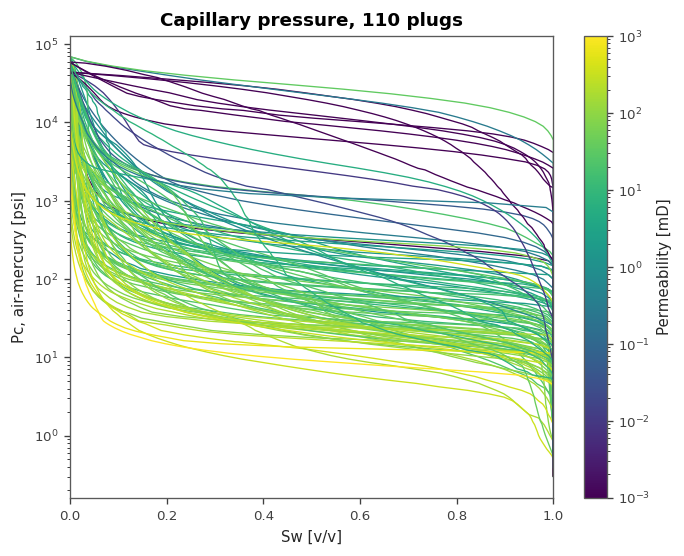

In [8]:
cap.plot();

Each line is one plug, from 0.3 to 69,000 psi of mercury pressure. Better
rock (yellow, high permeability) lets mercury in at lower pressure and drains
to a lower water saturation at any pressure; the tightest plugs (purple) need
thousands of psi before mercury enters at all.

A **Thomeer** hyperbola describes each curve with three numbers: the entry
(displacement) pressure $P_d$, where mercury first enters the connected pore
system; the pore geometry factor $G$, the curvature; and $BV_\infty$, the
mercury-filled bulk volume (%) at infinite pressure. `cap.thomeer()` fits one
per plug:

In [9]:
thomeer = cap.thomeer()
thomeer.describe()

,Pd,G,BV_INF,R2,POROSITY,PERMEABILITY
count,110.000,110.000,110.000,110.000,110.000,1.100e+02
mean,309.659,0.546,20.759,0.994,0.177,6.751e+01
std,1038.206,0.624,9.323,0.011,0.084,1.334e+02
min,1.014,0.044,0.900,0.918,0.003,1.000e-05
25%,10.466,0.144,13.290,0.995,0.117,2.620e+00
50%,21.759,0.336,21.257,0.997,0.187,2.247e+01
75%,75.279,0.611,26.362,0.999,0.227,6.933e+01
max,7463.722,3.193,42.113,1.000,0.352,1.006e+03


All 110 plugs fit, with a median $R^2$ of 0.997. The entry pressure spans
more than three decades, from 1.0 to 7,464 psi air-mercury (median 22 psi):
the range of rock quality in the field.

The bundled `costa_thomeer_fits` workbook holds the processed Thomeer fits of
the same plugs. Ten of its plugs needed two pore systems (`Pd2` filled); on
the others, a single hyperbola is comparable with ours. Joined on the sample
number:

In [10]:
vendor = pd.read_excel(pp.sample("costa_thomeer_fits")).set_index("Sample")
both = thomeer.join(vendor[vendor["Pd2"].isna()][["Pd1", "G1", "BV1"]], how="inner")
pd.Series({"plugs": len(both), "median Pd ratio": (both["Pd"] / both["Pd1"]).median(),
           "median G difference": (both["G"] - both["G1"]).median(),
           "median BV_INF ratio": (both["BV_INF"] / both["BV1"]).median(), "median R2": both["R2"].median()})

plugs                  99.000
median Pd ratio         1.016
median G difference    -0.006
median BV_INF ratio     1.007
median R2               0.998
dtype: float64

On the 99 single-pore-system plugs the two fits agree: the median ratio of
the entry pressures is 1.016, the median $G$ differs by -0.006, and the median
$BV_\infty$ ratio is 1.007.

Entry pressures measured with mercury are far above what oil and brine
develop in the reservoir. `cap.to_reservoir("oil_brine")` converts the curves
with the $\sigma\cos\theta$ ratio of section 2, and `entry_pressure()` gives the
Thomeer $P_d$ of each plug at those conditions:

In [11]:
entry = cap.to_reservoir("oil_brine").entry_pressure()
entry.describe()

count    110.000
mean      21.880
std       73.357
min        0.072
25%        0.739
50%        1.537
75%        5.319
max      527.366
Name: ENTRY_PRESSURE, dtype: float64

Converted to oil and brine, the median plug entry pressure is 1.54 psi (the
middle half of the plugs lie between 0.74 and 5.3 psi); the tightest plug needs
527 psi.

### 2c. A J-function from core

`fit_j_function_from_core` converts the curves to reservoir conditions,
computes each point's Leverett $J$ from its $P_c$, permeability and porosity,
and fits $S_w = a\,J^b$ to all plugs at once. Points where oil has not yet
entered ($S_w$ = 1) and pressures beyond a 1000 ft hydrocarbon column are left
out. The model also needs the reservoir fluid densities to turn height into
$P_c$. We **assume** a brine specific gravity of 1.14 (COSTA formation water is
about 200,000 ppm) and a light oil of 0.75; no PVT data are bundled.

In [12]:
core_model = fit_j_function_from_core(cap, "oil_brine", sg_water=1.14, sg_hc=0.75)
core_model

JFunctionModel(Sw = 0.1724 * J^-0.6526, R2=0.679, n=4562)

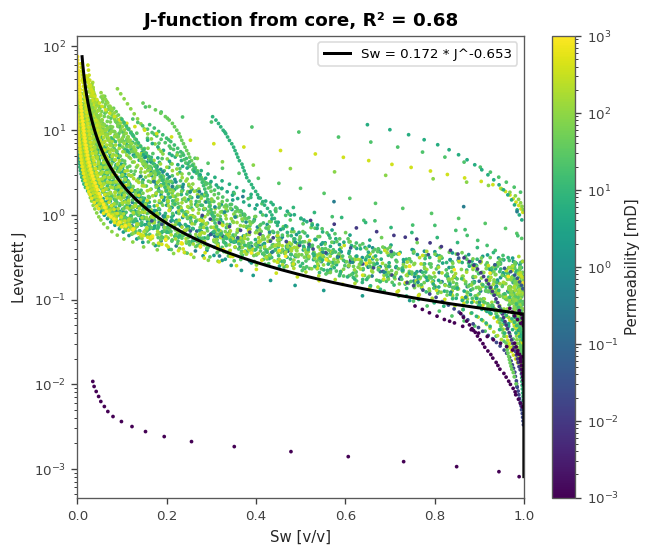

In [13]:
core_model.plot();

Over 4562 points of the 110 plugs, $S_w = 0.172\,J^{-0.653}$ with $R^2$ = 0.68.
The plot shows the scatter around the line: plugs of one permeability follow
their own curves, and a single J-function averages them; one very tight plug
(purple, lowest) lies far below the trend.

### 2d. Finding the FWL with the core model

A core model and a well's logs together can place the free-water level. For a
trial FWL the model predicts $S_w$ at every log sample from its height above
that level, permeability and porosity; `find_fwl` moves the trial
FWL and keeps the one where the predicted and log $S_w$ agree best, with a 95%
range from the misfit. It needs a **transition zone** in the logs - depths where
$S_w$ climbs towards 1 - to pin the level. Like the other height functions, it
takes the depth index as true vertical depth when no `tvd_curve` is named, and
warns.

**HW-24** logs its whole transition zone:

In [14]:
hw24 = pp.read(pp.sample("HW-24"))
fwl24 = find_fwl(hw24, core_model, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC")
fwl24

[temporary directory]\ipykernel_2436\2545586599.py:2: UserWarning: find_fwl: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only.
  fwl24 = find_fwl(hw24, core_model, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC")


FWLFromLogs(FWL 8585.1 ft, 95% range 8574.0-8604.1, RMS Sw misfit 0.084, R2 0.74, n=343)

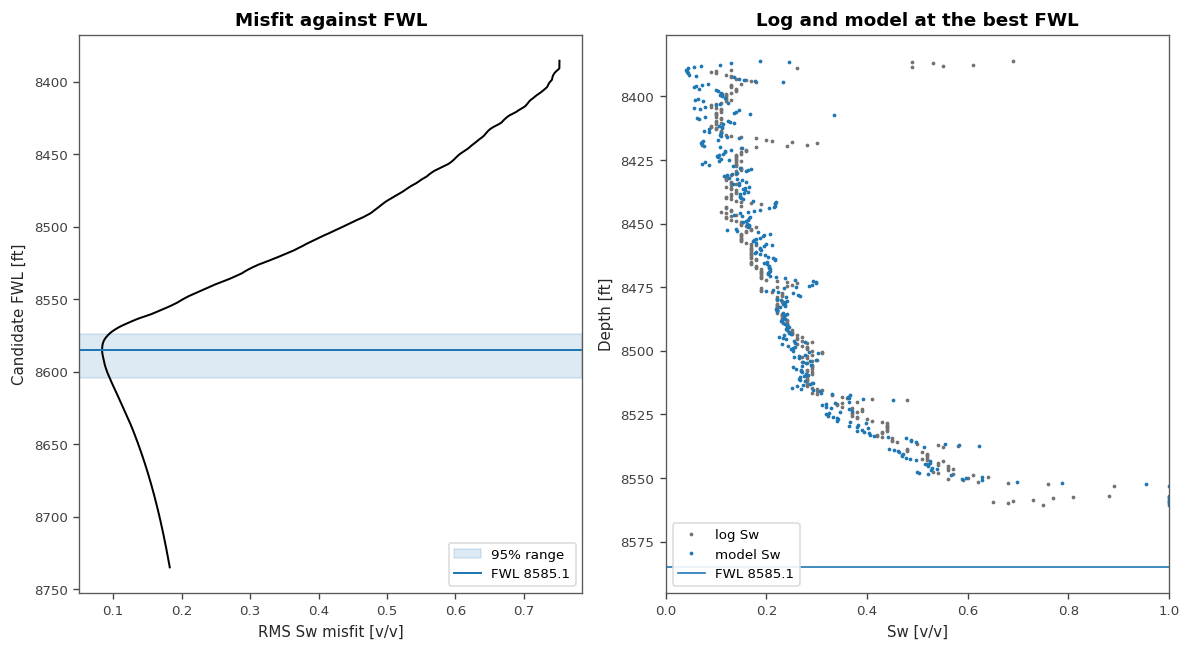

In [15]:
fwl24.plot();

The best FWL is 8585.1 ft (95% range 8574.0-8604.1 ft), with an RMS $S_w$
misfit of 0.084 over 343 samples. The logs show the whole transition: $S_w$
rises from about 0.1 near 8400 ft to about 0.9 near 8555 ft, at the base of the
log, and the model at the best FWL follows them. The deepest log samples lie above the FWL: the
level is placed by the shape of the transition zone, not by a log reading
in the water.

The FWL is where the capillary pressure is zero; the shallowest depth where the
logs read $S_w$ = 1, the **water contact**, lies above it. Oil enters a rock
only once the capillary pressure exceeds its entry pressure, so the contact
sits higher by the entry-pressure height, $h = P_d / (0.433\,(\mathrm{SG}_w -
\mathrm{SG}_{hc}))$. With the median plug entry pressure at reservoir
conditions:

In [16]:
water_contact_from_fwl(fwl24.fwl, entry.median(), sg_water=1.14, sg_hc=0.75)

8576.04408518369

With the assumed densities the buoyancy gradient is 0.433 x (1.14 - 0.75) =
0.169 psi/ft, so 1.54 psi corresponds to about 9 ft: the water contact lies at
8576.0 ft, 9 ft above the FWL. A rock with a higher entry pressure than the
median places its own contact higher still, which is why contacts read from
logs can vary with rock type above one FWL.

**HW-3** is the case the logs cannot pin:

In [17]:
find_fwl(pp.read(pp.sample("HW-3")), core_model, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC")

[temporary directory]\ipykernel_2436\3393746471.py:1: UserWarning: find_fwl: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only.
  find_fwl(pp.read(pp.sample("HW-3")), core_model, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC")


FWLFromLogs(FWL deeper than 8116.7 ft (no transition zone logged), RMS Sw misfit 0.078, R2 0.32, n=313)

The misfit keeps falling to the bottom of the search, so the result is only a
bound: the FWL lies deeper than 8116.7 ft. HW-3's log $S_w$ stays low almost
to the base of the file and shows no transition zone the model could match.
To place this FWL, use formation pressures (section 3b) or a log that reaches
the transition.

## 3. Load the Kharaib-2 interval of HW-3

The HW-3 LAS in the COSTA sample set covers only the **Kharaib-2** carbonate
reservoir interval, not the whole well; the bundled COSTA tops
(`formations_costa`) label that interval, and we attach them while reading. The
file carries core-corrected log porosity (`PHIE_CC`) and permeability
(`PERM_CC`) and a source water-saturation curve (`SW_INPUT`) - the log $S_w$ we
will fit the J-function to and later compare the model back against. Depth is
in **feet**.

HW-3 carries no laboratory $P_c$ measurements of its own. Where no plug data
exist, a J-function is often fitted to the logs themselves with an assumed FWL;
we do that here, as a contrast to the core model of section 2c. (For a single
measured lab drainage curve the library also provides `fit_brooks_corey`,
parameters $S_{wir}$, $P_d$, $\lambda$.)

In [18]:
well = pp.read(pp.sample("HW-3"), formations=pp.sample("formations_costa"))
well.describe()["formations"], well.top, well.bottom, well.depth_unit

(['KHARAIB-2'], 7805.0, 8020.0, 'ft')

In [19]:
logs = well.to_dataframe(["PHIE_CC", "PERM_CC", "SW_INPUT"]).dropna()
logs.describe()

,DEPTH,PHIE_CC,PERM_CC,SW_INPUT
count,313.000,313.000,313.000,313.000
mean,7906.353,0.271,37.978,0.103
std,45.570,0.058,102.968,0.095
min,7809.000,0.030,0.040,0.040
25%,7867.500,0.270,6.000,0.070
50%,7906.500,0.300,8.600,0.080
75%,7945.500,0.300,23.500,0.100
max,7990.000,0.330,990.000,0.900


The file covers 7805-8020 ft, all of it Kharaib-2. 313 samples carry porosity,
permeability and log $S_w$ together, from 7809 to 7990 ft.

### Build a J-function from the rock-quality curves

We fit the J-function on the HW-3 Kharaib-2 data. To turn each sample's
Sw into a $J$ value we need its $P_c$, which we obtain from an **assumed FWL
depth** 1 ft below the deepest valid sample (7990 ft), where the log $S_w$ has
climbed to 0.9 (buoyancy converts height above FWL into $P_c$). We read that
rise as the base of a transition zone. It is not the only reading: porosity falls
from 0.24 to 0.05 over the same 12 ft, and the core model of section 2d takes the
rise for tight rock, with the FWL much deeper. This follows the field workflow used when only
saturation and rock-quality data exist, except that there the FWL is picked
from pressure data; here it is an assumption, and every $J$ value inherits it.

`fit_j_function_from_well` does the whole chain: each sample's height above
the FWL gives its $P_c$ (the brine SG 1.14 and oil SG 0.75 assumed in section 2c), its $P_c$, permeability and
porosity give its $J$ (with the oil-brine interfacial tension and contact
angle, `fluids="oil_brine"`, 30 dyne/cm and 30 deg), and $S_w = a\,J^b$ is
fitted in log space. Like the prediction in section 4, it takes the depth index
as true vertical depth when no `tvd_curve` is named, and warns.

In [20]:
fwl_depth = logs["DEPTH"].max() + 1.0   # ft, assumed FWL: the base of the transition zone
model = fit_j_function_from_well(well, fwl_depth=fwl_depth, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC",
                                 sg_water=1.14, sg_hc=0.75)
model

[temporary directory]\ipykernel_2436\2597757227.py:2: UserWarning: fit_j_function_from_well: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  model = fit_j_function_from_well(well, fwl_depth=fwl_depth, sw_curve="SW_INPUT", perm_curve="PERM_CC", phi_curve="PHIE_CC",


JFunctionModel(Sw = 0.0794 * J^-0.2321, R2=0.282, n=313)

The fit gives $S_w = 0.079\,J^{-0.232}$ with $R^2$ = 0.28 - low, because
carbonates are heterogeneous and our single assumed FWL cannot reconcile every
rock type. That is realistic; the model still captures the first-order trend
that better rock (higher $J$) drains to lower $S_w$.

Compare it with the core model of section 2c: the log fit is much flatter,
and it rests on an FWL that section 2d could not confirm - the core model puts
HW-3's FWL deeper than 8116.7 ft, more than 100 ft below the 7991 ft assumed
here. A model fitted to logs inherits every error of its assumed FWL; a core
model can test the FWL instead.

### 3a. Pick a formation pressure from a raw pretest

A station pressure starts as a raw pretest record: probe pressure against time
while the tool draws down and the formation builds back up. `read_mdt_pretest`
reads such a record and `pick_pressure()` accepts a stable buildup plateau or
returns the test for review. The bundled record is MDT file 059 from IODP Hole
C0009A (quartz gauge `BQP1`, tool depth `TDEP` in ft MD). The original DLIS,
`pp.sample("319-C0009A_MDT_059LTP")`, reads the same way with the `dlis` extra.

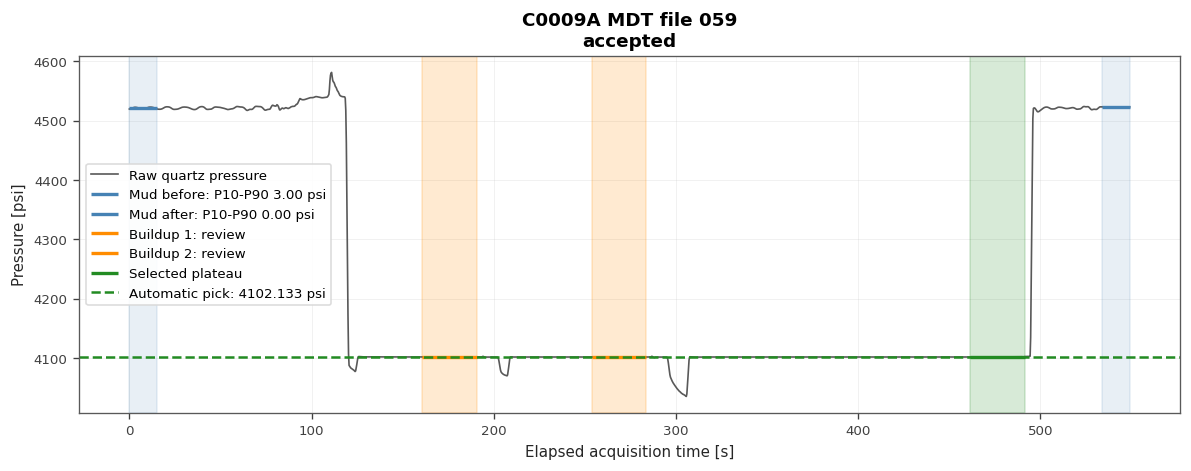

In [21]:
from petrophys.interpretation.saturation.height import read_mdt_pretest

pretest = read_mdt_pretest(pp.sample("c0009a_mdt_059"), time_column="TIME",
                           pressure_column="BQP1", depth_column="TDEP")
pick = pretest.pick_pressure()
pp.pretest_plot(pretest, pick, title="C0009A MDT file 059");

In [22]:
pick.status, pick.pressure, pick.pressure_unit, pick.station_depth, pick.depth_unit

('accepted', 4102.1328, 'psi', 9229.1, 'ft')

The buildup plateau is accepted: 4102.13 psi at 9229.1 ft MD.

### 3b. Infer contacts from formation-pressure stations

The bundled station files hold one stabilized MDT pressure per test, one LAS
file per well: depth, formation and mud pressures, mobility and a test-quality
code. They carry no fluid labels. The library compares contiguous robust
pressure-gradient models and reports possible contacts or ambiguity.

The 35/11-13 LAS uses `QC=0` for valid pressure tests. We build the `USE_FIT`
selection from that curve: 21 good tests are included, including the shallow
gas stations. No fluid labels or report contacts are supplied to the fitter.


In [23]:
import lasio
from petrophys.interpretation.saturation.height import read_formation_pressure

station_las = lasio.read(pp.sample("35_11_13_mdt"))
station_las.append_curve("USE_FIT", (station_las["QC"] == 0).astype(int))   # valid tests only
pressure_data = read_formation_pressure(station_las)
pressure_fit = pressure_data.infer_contacts()
int(pressure_data.points.use_fit.sum()), pressure_fit.status, pressure_fit.fluid_sequences, pressure_fit.fwl_depth

(21, 'interpreted', (('oil', 'water'),), 3113.1740677202133)

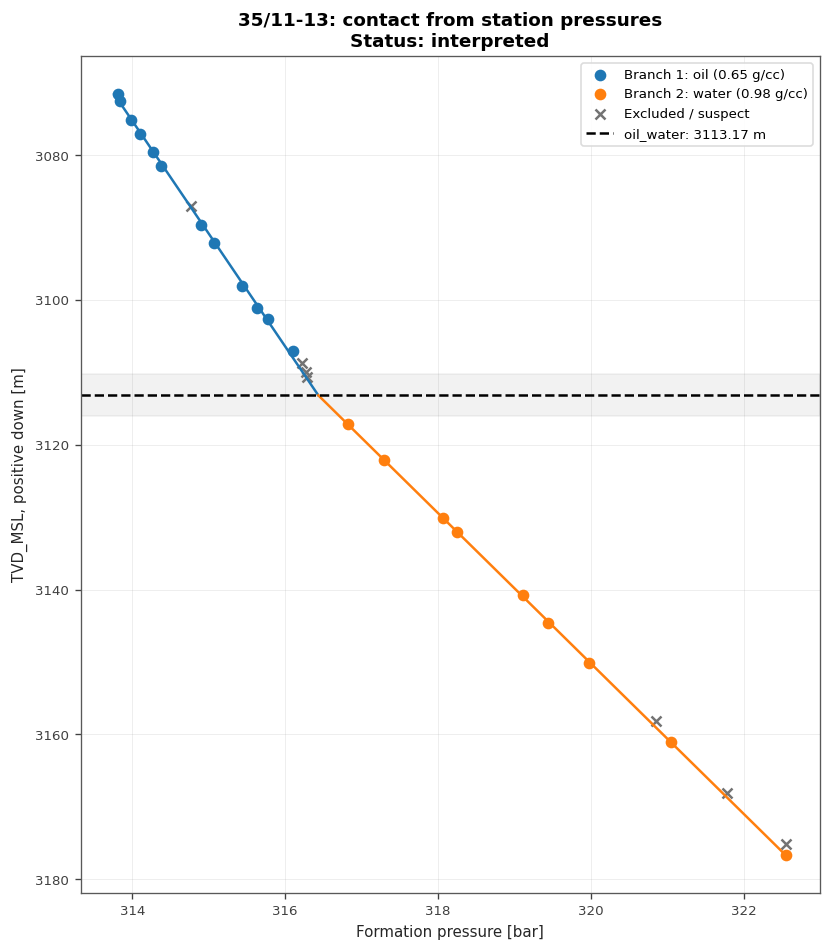

In [24]:
pp.contact_plot(pressure_data, pressure_fit, title="35/11-13: contact from station pressures");

The 21 selected stations give one candidate fluid sequence, oil over water, and
an oil/water contact at **3113.17 m TVD MSL**, about **0.6 m deeper** than the
3112.6 m FWL of the report, which the method never received. No contact
intervals or fluid labels were passed into it. The selected two-gradient model
groups 12 shallow and 9 deeper stations; it does **not resolve the two-station
gas leg separately**. This is an example of the limits of sparse pressure
measurements, not proof that every station in the upper branch contains oil.
Branch-count scores and density hypotheses are available on the result for
review.

Shaded plot intervals are conditional +/-2-sigma sensitivity to pressure error
and fitted line scatter. They exclude fluid-prior, segmentation, connectivity
and depth-datum uncertainty; they are not field-accuracy guarantees.

### Second well: return ambiguity instead of forcing a contact

The 35/11-10 file holds every station of the well's MDT runs 1A-2E: pretests
and sampling stations from about 1950 to 2850 m TVD MSL. Contact inference
assumes one connected reservoir, so we select the Fensfjord interval
(2250-2352 m TVD MSL) and its static pretests: valid pressure (`QC=0`) and not a
sampling station (`SAMPLE=0`), since pressures read during sampling include
drawdown. The report's **2290 m TVD MSL** contact is used only in the
comparison after inference.

In [25]:
second_las = lasio.read(pp.sample("35_11_10_mdt"))
fensfjord = (second_las.index >= 2250) & (second_las.index <= 2352)
second_las.append_curve("USE_FIT", (fensfjord & (second_las["QC"] == 0) & (second_las["SAMPLE"] == 0)).astype(int))
second_data = read_formation_pressure(second_las)
second_fit = second_data.infer_contacts()
int(second_data.points.use_fit.sum()), second_fit.status, second_fit.fwl_depth, [c.depth for c in second_fit.contacts]

(13, 'ambiguous', None, [2290.698771550649])

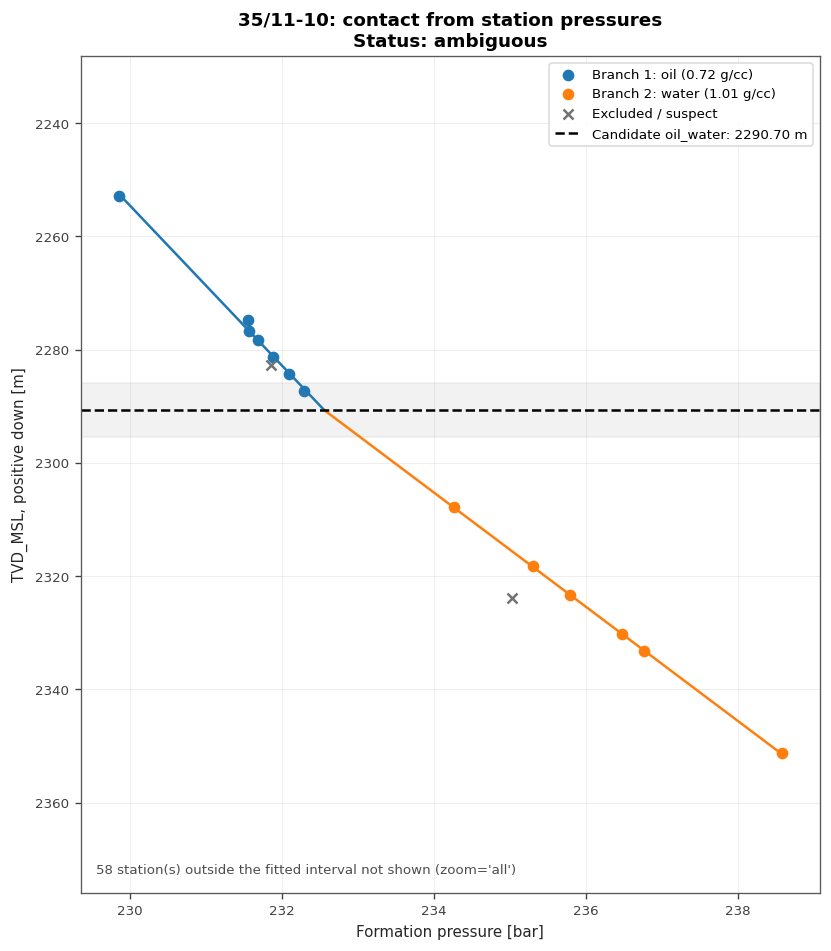

In [26]:
pp.contact_plot(second_data, second_fit, title="35/11-10: contact from station pressures");

The two-branch intersection is approximately **2290.7 m**, within a metre of
the report's 2290 m contact. With 13 pretests, seven above the contact and six
below, the branch identification stays uncertain at the assumed pressure error,
so the method reports the result as ambiguous and leaves `fwl_depth=None`.
Changing `pressure_noise` changes model identifiability; it must be grounded in
measurement/picking quality, not tuned to a report contact. Reservoir PVT
density bounds can constrain `fluid_density_ranges` without assigning
individual stations. Independent samples/downhole fluid analysis and geological
connectivity provide stronger evidence than pressure alone.

For your own CSV or station LAS use `read_formation_pressure(path).infer_contacts()`.
Fluid labels are not needed. Map custom depth/pressure columns and provide units
and a TVD datum if absent. A `USE_FIT` mask must express measurement QC and the
reservoir interval, not known fluid intervals. For inputs with interpreted fluid
labels, `.fit_fwl()` fits the labelled gradients. Arbitrary hydraulic-compartment
discovery is outside this method.

Pressure alone **cannot determine a saturation-height function**. Separate
capillary-pressure/rock calibration and fluid properties are required.

**The next section returns to HW-3.** Its unrelated assumed FWL in feet remains
separate from these metre-based pressure examples.

## 4. Predict Sw vs depth from logs and overlay

`saturation_height_from_logs` takes the fitted J-function, an FWL depth, and the
well's permeability/porosity curves, and returns a **predicted $S_w$ at every
depth**. Height above the FWL is `fwl_depth - depth`; below the FWL height is
clipped to zero -> $S_w = 1$.

**Height is vertical.** `saturation_height_from_logs` measures it on a
true-vertical-depth curve when you name one (`tvd_curve=`); otherwise it takes
the well's depth index as TVD, which holds for a vertical well only, and says so
with a `UserWarning`. HW-3 carries no TVD curve or deviation survey, so we treat
it as vertical, with the assumed FWL on the same depth index, and the warning the
next cell prints records that assumption. A depth in metres would be converted to
feet for the field-unit capillary relation; HW-3 is already in feet.

One honesty note before reading the error statistics below: `SW_INPUT` is the
**same curve the J-function was fitted to**, so the mean absolute error is an
**in-sample goodness-of-fit check**, not independent prediction skill. Hold out
depths (or a whole well) from the fit for a real validation.

In [27]:
sw_pred = saturation_height_from_logs(well, model, fwl_depth=fwl_depth)
error = pd.Series(sw_pred - well.get("SW_INPUT").data)
pd.Series({"mean absolute error": error.abs().mean(), "bias": error.mean(), "median predicted Sw": np.nanmedian(sw_pred)})

[temporary directory]\ipykernel_2436\3849586284.py:1: UserWarning: saturation_height_from_logs: no tvd_curve given, so the depth index is taken as true vertical depth, which holds for a vertical well only. Pass tvd_curve, on the datum of fwl_depth, for a deviated well.
  sw_pred = saturation_height_from_logs(well, model, fwl_depth=fwl_depth)


mean absolute error    0.027
bias                  -0.010
median predicted Sw    0.087
dtype: float64

The predicted $S_w$ (median 0.087) differs from the log $S_w$ by 0.027 on
average, with a bias of -0.010: an in-sample check, as said above. To overlay
the two, we add the prediction to the well as `SW`, so the plot draws it in the
saturation track beside the dashed `SW_INPUT`, next to the rock-quality curves.

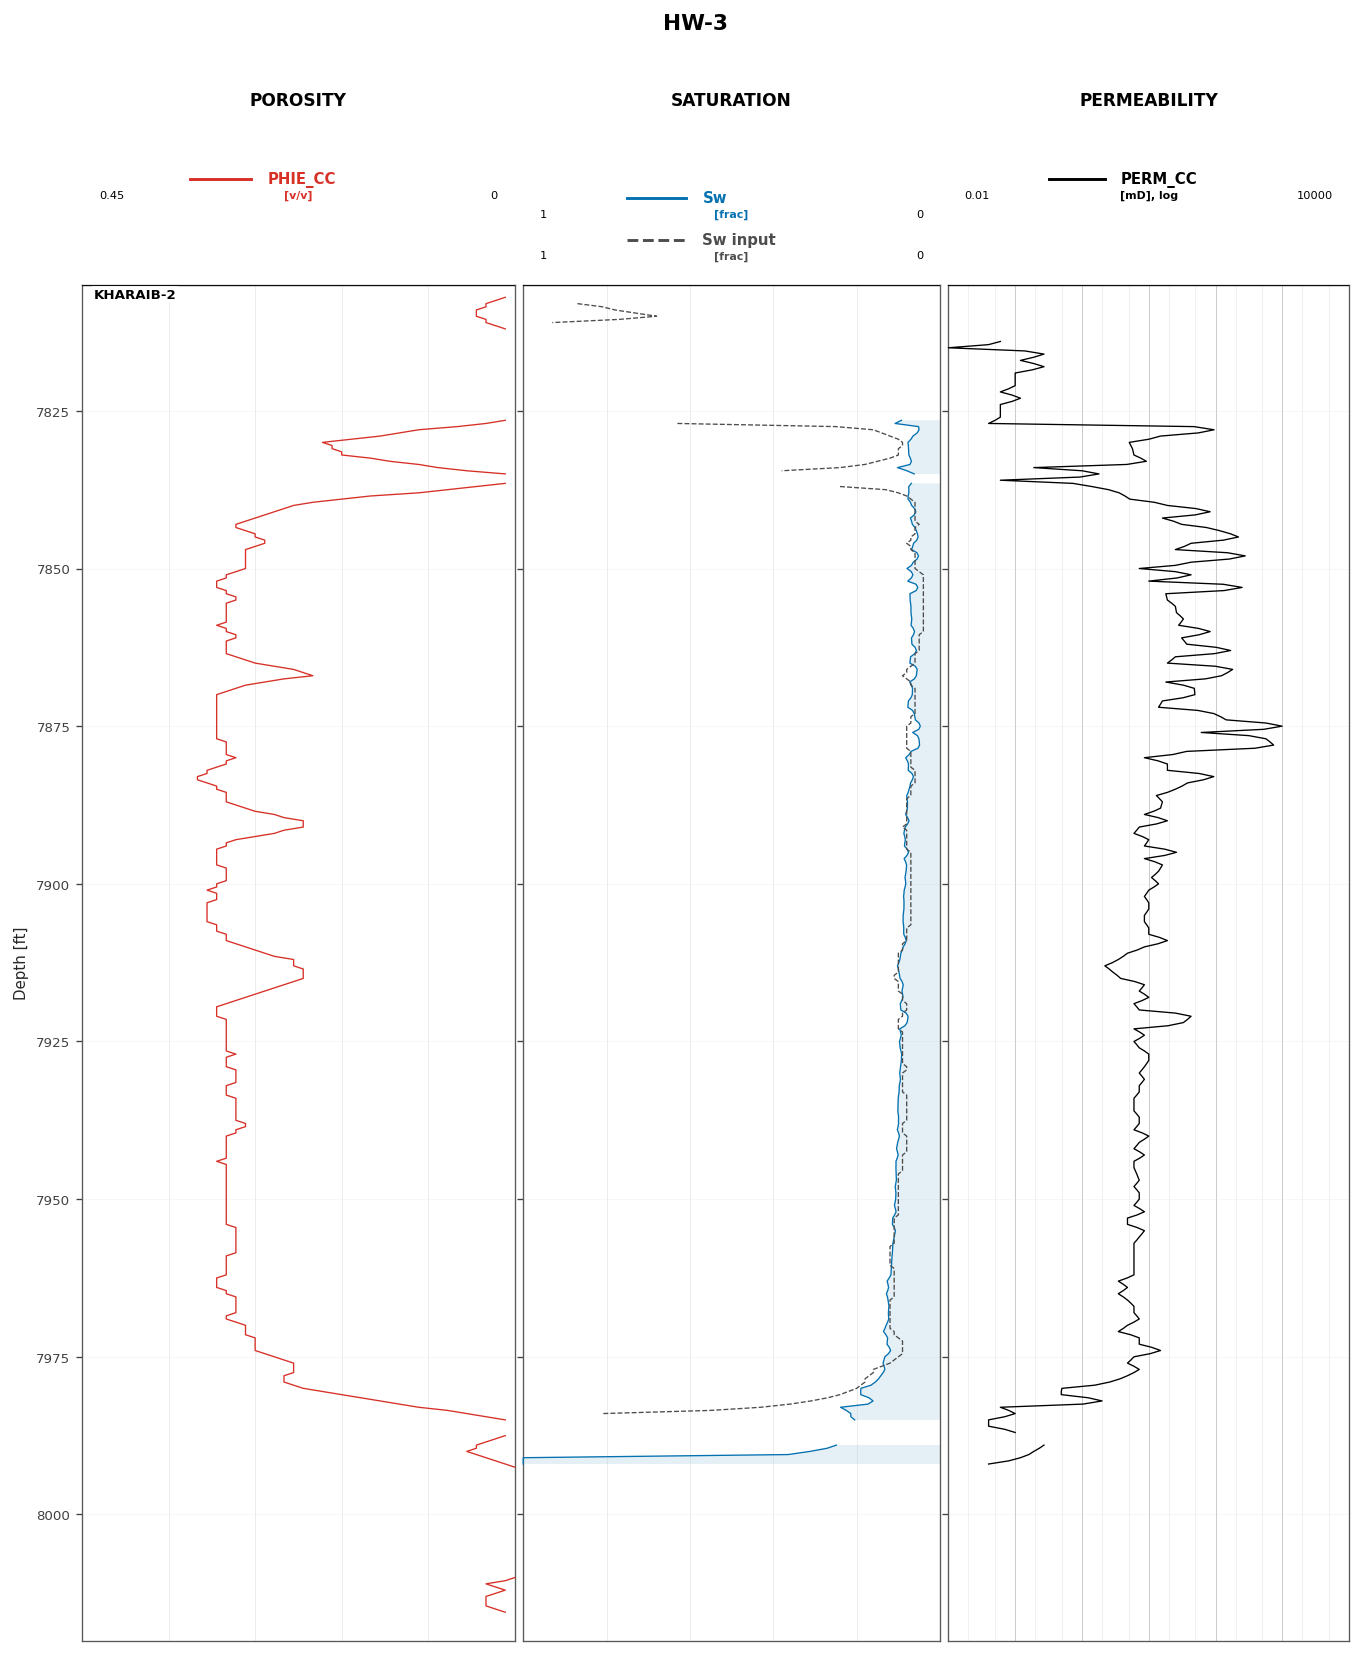

In [28]:
well.add_curve("SW", sw_pred, "v/v", "Sw from the saturation-height model")
pp.plot(well, curves=["SW_INPUT", "SW", "PHIE_CC", "PERM_CC"]).show()

Where the two $S_w$ curves diverge is diagnostic: if the saturation-height
model reads **drier** than the log $S_w$, either the FWL is picked too deep, the
rock-quality curves are off, or there is a genuine transition-zone /
low-resistivity-pay effect worth investigating.

## 5. The saturation-height diagnostic plot

`model.plot()` draws the standard QC of a saturation-height fit: the fitted
samples, $S_w$ against height above the FWL and coloured by permeability, and
the model's $S_w$-height curve for 1, 10 and 100 mD rock, each at the median
porosity of the samples near that permeability. HW-3 has no core saturations or
lab $P_c$, so the points are the `SW_INPUT` log saturations, placed at their
height above the assumed FWL. This is the layout of a saturation-height report
plot, but a report version needs measured $P_c$ or a pressure-derived FWL
behind it. (`saturation_height_plot` in `petrophys.visualization` draws
the two-panel report version, the J-function fit beside type curves for rock
classes you choose.)

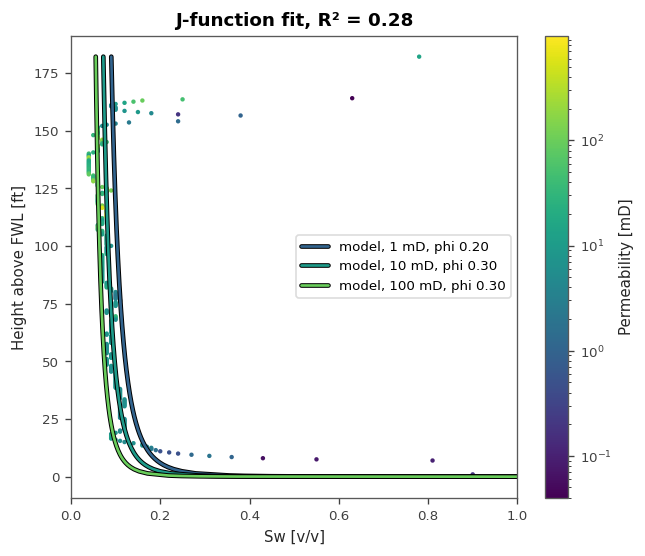

In [29]:
model.plot();

The model curves show the model's core prediction: at any given height above
the FWL, **better rock (higher $k$) holds less water** - exactly the capillary
physics we started with. In a calibrated study, curves like these are what get
handed to the reservoir model to populate $S_w$ away from well control. These
ones are not ready for that: the fit explains only a small part of the scatter
($R^2$ 0.28, in the title), it is fitted to log saturations rather than
measured $P_c$, and the FWL behind every point is assumed. Treat them as a
demonstration of the method.

## Pitfalls & parameter choices

- **The FWL must come from data.** For HW-3 we *assumed* an FWL 1 ft below the
  deepest valid sample, where log $S_w$ reaches 0.9, to make the demo self-contained; in practice pick it from formation
  pressures (RFT/MDT gradient intersection), the deepest known water, or a core
  model matched to a logged transition zone (section 2d). A wrong
  FWL biases every predicted $S_w$.
- **J-function vs Brooks-Corey.** J-function normalises by $\sqrt{k/\phi}$, so **one**
  fit covers many rock qualities and is the model applied back to logs.
  Brooks-Corey describes a **single** drainage curve - fit it per rock type / per
  plug.
- **Always lab-to-reservoir convert Pc.** Never fit reservoir saturations to raw
  air-mercury Pc; use `convert_pc_lab_to_reservoir` first.
- **Units.** The capillary-pressure functions use field units: Pc in psi, height in ft, $k$
  in mD, $\phi$ as a **fraction**, IFT in dyne/cm, angle in degrees.
  `saturation_height_from_logs` converts a depth in metres to feet itself.
- **Height is vertical.** Pass `tvd_curve=` for a deviated well, on the datum of
  the FWL; without it the depth index is taken as TVD, with a warning.
- **Modest $R^2$ is normal** in heterogeneous carbonates; consider fitting
  separate J-functions per flow unit / rock type.

## Recap

- **Height above the FWL is a rescaled capillary pressure**:
  $P_c = 0.433(\mathrm{SG}_w-\mathrm{SG}_{hc})h$.
- The **Leverett J-function** normalises $P_c$ by $\sqrt{k/\phi}$ so different rock
  qualities collapse onto one curve.
- **Brooks-Corey** ($S_{wir}, P_d, \lambda$) describes a single drainage curve;
  the **J power-law** ($S_w = aJ^b$) is what we apply back to logs.
- Lab Pc must be **converted to reservoir** fluid conditions before use.
- Plug mercury curves give a **Thomeer** fit and an entry pressure per plug, and one
  **J-function from core** for the field (`fit_j_function_from_core`).
- A core model matched to a logged transition zone **finds the FWL**
  (`find_fwl`; 8585.1 ft on HW-24), and the water contact lies
  above it by the entry-pressure height; without a transition zone (HW-3) the
  logs give only a bound.
- `saturation_height_from_logs` turns a fitted model + FWL + $(k,\phi)$ curves
  into a predicted $S_w$ profile you can overlay on the resistivity-based
  $S_w$ (here an in-sample comparison, since the same curve trained the fit).
- The 35/11-13 MDT example fits FWL from oil/water pressure gradients and
  checks it against the source report, keeping TVD, units and QC explicit.

## Try it yourself

> **Exercise 1.** Move the assumed FWL up and down by +/-30 ft and re-run the
> prediction. How sensitive is the mean absolute error to the FWL pick?
>
> **Exercise 2.** Fit the J-function with `form='power_swir'` and an explicit
> `swir=0.1` floor. Does forcing an irreducible asymptote improve the deep,
> tight-rock predictions?
>
> **Exercise 3.** Using the fitted HW-3 Kharaib-2 J-function (`model`), compute the height
> above the FWL at which $S_w$ first falls below 0.5 for a 10 mD / 0.15 rock
> versus a 100 mD / 0.25 rock (hint: invert $S_w = a\,J^b$ for $J$, then
> `pc_from_j` and `height_from_pc`).

## What's next

Continue with **16 - Borehole Images and FMI**. Part B then runs through
lesson 21: 17 (visualization masterclass), 18 (multiwell field study), 19 (LLM
context generation), 20 (Petrophys for LLM agents over MCP) and 21 (custom
workflows). Along the way,
revisit the Part A water-saturation lesson (07) and compare its Archie $S_w$
against this saturation-height prediction - reconciling the two is the heart
of a defensible reservoir saturation model.